In [1]:
!pip install seaborn

In [2]:
import pandapower as pp
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np


# Création d'un réseau vide
net = pp.create_empty_network()

# Ajout du poste HTA/BT (transformateur)
hv_bus = pp.create_bus(net, vn_kv=20., name="Poste HTA/BT", type="b")
bus1 = pp.create_bus(net, vn_kv=0.4, name="Bus 1 (Poste)", type="b")
pp.create_transformer_from_parameters(
    net,
    hv_bus=hv_bus,
    lv_bus=bus1,
    sn_mva=0.63,
    vn_hv_kv=20.0,
    vn_lv_kv=0.4,
    vk_percent=6.0,
    vkr_percent=1.206,
    pfe_kw=1.65,
    i0_percent=0.2619,
    shift_degree=150,
    vector_group="Dyn5",
    tap_side="hv",
    tap_neutral=0,
    tap_min=-2,
    tap_max=2,
    tap_step_percent=2.5,
    tap_changer_type="Ratio",
    tap_pos=0,
    name="trafo"
)

# Ajout d'une source de référence (bus de slack)
pp.create_ext_grid(net, bus=hv_bus, vm_pu=1.0, name="Grid")

# Ajout des bus (nœuds)
bus2 = pp.create_bus(net, vn_kv=0.4, name="Bus 2 (Dérivation 1)", type="b")
bus3 = pp.create_bus(net, vn_kv=0.4, name="Bus 3 (Intersection 1)", type="b")
bus4 = pp.create_bus(net, vn_kv=0.4, name="Bus 4 (Étoilement central)", type="b")
bus5 = pp.create_bus(net, vn_kv=0.4, name="Bus 5 (Dérivation 2)", type="b")
bus6 = pp.create_bus(net, vn_kv=0.4, name="Bus 6 (Intersection 2)", type="b")
bus7 = pp.create_bus(net, vn_kv=0.4, name="Bus 7 (Dérivation 3)", type="b")

# Ajout des lignes (connexions)
pp.create_line(net, from_bus=bus1, to_bus=bus2, length_km=0.05, std_type="NAYY 4x50 SE", name="Ligne 1-2")
pp.create_line(net, from_bus=bus2, to_bus=bus3, length_km=0.03, std_type="NAYY 4x50 SE", name="Ligne 2-3")
pp.create_line(net, from_bus=bus3, to_bus=bus4, length_km=0.04, std_type="NAYY 4x50 SE", name="Ligne 3-4")
pp.create_line(net, from_bus=bus4, to_bus=bus5, length_km=0.02, std_type="NAYY 4x50 SE", name="Ligne 4-5")
pp.create_line(net, from_bus=bus4, to_bus=bus6, length_km=0.03, std_type="NAYY 4x50 SE", name="Ligne 4-6")
pp.create_line(net, from_bus=bus6, to_bus=bus7, length_km=0.02, std_type="NAYY 4x50 SE", name="Ligne 6-7")

# Ajout des charges (maisons)
pp.create_load(net, bus=bus2, p_mw=0.015, q_mvar=0.005, name="Maison 1")
pp.create_load(net, bus=bus3, p_mw=0.020, q_mvar=0.008, name="Maison 2")
pp.create_load(net, bus=bus5, p_mw=0.010, q_mvar=0.003, name="Maison 3")
pp.create_load(net, bus=bus5, p_mw=0.012, q_mvar=0.004, name="Maison 4")
pp.create_load(net, bus=bus6, p_mw=0.018, q_mvar=0.006, name="Maison 5")
pp.create_load(net, bus=bus7, p_mw=0.014, q_mvar=0.005, name="Maison 6")

# Exécution du Load Flow (optionnel, pour avoir des données électriques)
pp.runpp(net)

🕵️ 3. Identification des structures avec NetworkX
🔹 Étape 1 : Extraire le graphe du réseau

In [3]:
import networkx as nx

# Création du graphe à partir du réseau Pandapower
G = nx.Graph()

# Ajout des nœuds (bus)
for bus_idx, bus in net.bus.iterrows():
    G.add_node(bus_idx, name=bus["name"], type=bus["type"])

# Ajout des arêtes (lignes)
for line_idx, line in net.line.iterrows():
    G.add_edge(line["from_bus"], line["to_bus"], name=line["name"], length_km=line["length_km"])


🔹 Étape 2 : Calculer le degré de chaque nœud

In [4]:
# Calcul du degré (nombre de connexions) pour chaque nœud
degrees = dict(G.degree())

# Affichage des degrés
print("Degrés des nœuds :")
for node, degree in degrees.items():
    print(f"Bus {node} ({net.bus.at[node, 'name']}): degré = {degree}")


Degrés des nœuds :
Bus 0 (Poste HTA/BT): degré = 0
Bus 1 (Bus 1 (Poste)): degré = 1
Bus 2 (Bus 2 (Dérivation 1)): degré = 2
Bus 3 (Bus 3 (Intersection 1)): degré = 2
Bus 4 (Bus 4 (Étoilement central)): degré = 3
Bus 5 (Bus 5 (Dérivation 2)): degré = 1
Bus 6 (Bus 6 (Intersection 2)): degré = 2
Bus 7 (Bus 7 (Dérivation 3)): degré = 1


In [5]:
# Nœuds avec degré = 2 (potentielles dérivations)
derivations = [node for node, degree in degrees.items() if degree == 2 and node not in net.load.index and node not in net.gen.index]
print("\nNœuds identifiés comme dérivations :")
for node in derivations:
    print(f"- Bus {node} ({net.bus.at[node, 'name']})")



Nœuds identifiés comme dérivations :
- Bus 6 (Bus 6 (Intersection 2))


In [6]:
# Nœuds avec degré ≥ 3 (intersections)
intersections = [node for node, degree in degrees.items() if degree >= 3]
print("\nNœuds identifiés comme intersections :")
for node in intersections:
    print(f"- Bus {node} ({net.bus.at[node, 'name']})")



Nœuds identifiés comme intersections :
- Bus 4 (Bus 4 (Étoilement central))


In [7]:
def find_stars(G):
    stars = []
    for node in G.nodes():
        neighbors = list(G.neighbors(node))
        if len(neighbors) >= 2:  # Nœud central potentiel
            terminal_neighbors = [n for n in neighbors if G.degree(n) == 1]
            if len(terminal_neighbors) >= 2:  # Au moins 2 nœuds terminaux
                stars.append((node, terminal_neighbors))
    return stars

stars = find_stars(G)
print("\nÉtoilements identifiés :")
for center, terminals in stars:
    print(f"- Nœud central : Bus {center} ({net.bus.at[center, 'name']})")
    terminal_labels = [f"Bus {t} ({net.bus.at[t, 'name']})" for t in terminals]
    print(f"  Nœuds terminaux : {terminal_labels}")


Étoilements identifiés :


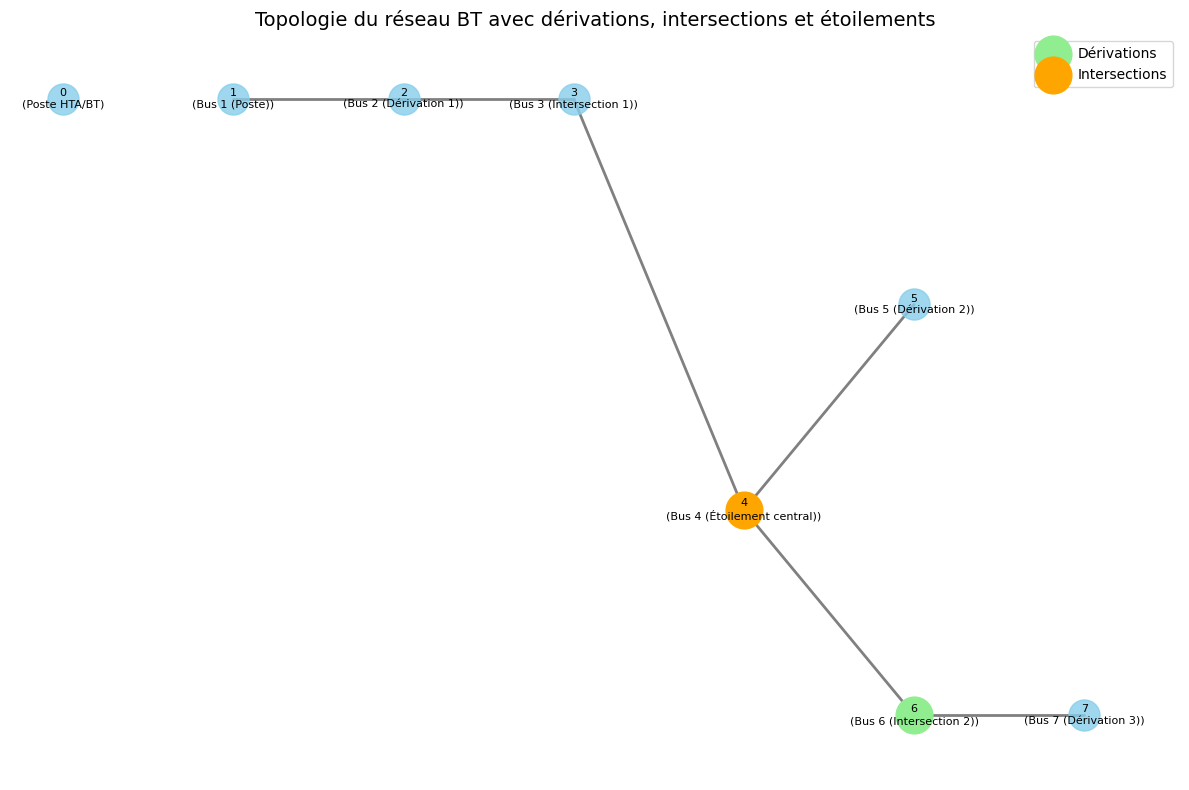

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))

# Positionnement des nœuds (pour une meilleure lisibilité)
pos = {
    0: (0, 5),    # Poste HTA/BT
    1: (1, 5),    # Bus 1
    2: (2, 5),    # Bus 2 (Dérivation 1)
    3: (3, 5),    # Bus 3 (Intersection 1)
    4: (4, 3),    # Bus 4 (Étoilement central)
    5: (5, 4),    # Bus 5 (Dérivation 2)
    6: (5, 2),    # Bus 6 (Intersection 2)
    7: (6, 2),    # Bus 7 (Dérivation 3)
}

# Dessin du graphe
nx.draw_networkx_nodes(G, pos, node_size=500, node_color="skyblue", alpha=0.8)
nx.draw_networkx_edges(G, pos, width=2, edge_color="gray")
nx.draw_networkx_labels(G, pos, labels={n: f"{n}\n({net.bus.at[n, 'name']})" for n in G.nodes()}, font_size=8)

# Mise en évidence des structures
nx.draw_networkx_nodes(G, pos, nodelist=derivations, node_size=700, node_color="lightgreen", label="Dérivations")
nx.draw_networkx_nodes(G, pos, nodelist=intersections, node_size=700, node_color="orange", label="Intersections")
for center, terminals in stars:
    nx.draw_networkx_nodes(G, pos, nodelist=[center], node_size=700, node_color="red", label="Étoilement central")
    nx.draw_networkx_edges(G, pos, edgelist=[(center, t) for t in terminals], width=3, edge_color="red")

plt.title("Topologie du réseau BT avec dérivations, intersections et étoilements", fontsize=14)
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()


In [28]:
# Création d'un DataFrame avec les résultats
results = []

for node in G.nodes():
    results.append({
        "Bus ID": node,
        "Nom": net.bus.at[node, "name"],
        "Degré": degrees[node],
        "Type": "Dérivation" if node in derivations else
                "Intersection" if node in intersections else
                "Étoilement central" if node in [center for center, _ in stars] else
                "Terminal",
        "Connexions": list(G.neighbors(node))
    })

df_results = pd.DataFrame(results)
print("\nRapport des structures :")
print(df_results)



Rapport des structures :
   Bus ID                         Nom  Degré          Type Connexions
0       0                Poste HTA/BT      0      Terminal         []
1       1               Bus 1 (Poste)      1      Terminal        [2]
2       2        Bus 2 (Dérivation 1)      2      Terminal     [1, 3]
3       3      Bus 3 (Intersection 1)      2      Terminal     [2, 4]
4       4  Bus 4 (Étoilement central)      3  Intersection  [3, 5, 6]
5       5        Bus 5 (Dérivation 2)      1      Terminal        [4]
6       6      Bus 6 (Intersection 2)      2    Dérivation     [4, 7]
7       7        Bus 7 (Dérivation 3)      1      Terminal        [6]


In [33]:
import pandas as pd

def analyze_network_topology(net):
    """
    Analyse la topologie d'un réseau Pandapower et identifie :
    - Dérivations (degré = 2)
    - Intersections (degré ≥ 3)
    - Étoilements (nœud central avec ≥ 2 nœuds terminaux)
    """
    # Création du graphe
    G = nx.Graph()
    for bus_idx, bus in net.bus.iterrows():
        if bus["in_service"]:
            G.add_node(bus_idx, name=bus["name"], type=bus["type"])
    for line_idx, line in net.line.iterrows():
        if line["in_service"]:
            G.add_edge(line["from_bus"], line["to_bus"], name=line["name"], length_km=line["length_km"])

    # Calcul des degrés
    degrees = dict(G.degree())

    # Identification des structures
    derivations = [node for node, degree in degrees.items() if degree == 2 and node not in net.load.index and node not in net.gen.index]
    intersections = [node for node, degree in degrees.items() if degree >= 3]
    stars = find_stars(G)

    # Création du rapport
    results = []
    for node in G.nodes():
        results.append({
            "Bus ID": node,
            "Nom": net.bus.at[node, "name"],
            "Degré": degrees[node],
            "Type": "Dérivation" if node in derivations else
                    "Intersection" if node in intersections else
                    "Étoilement central" if node in [center for center, _ in stars] else
                    "Terminal",
            "Connexions": list(G.neighbors(node))
        })

    return pd.DataFrame(results), G, derivations, intersections, stars

# Exemple d'utilisation
df_report, G, derivations, intersections, stars = analyze_network_topology(net)
print(df_report)


   Bus ID                         Nom  Degré          Type Connexions
0       0                Poste HTA/BT      0      Terminal         []
1       1               Bus 1 (Poste)      1      Terminal        [2]
2       2        Bus 2 (Dérivation 1)      2      Terminal     [1, 3]
3       3      Bus 3 (Intersection 1)      2      Terminal     [2, 4]
4       4  Bus 4 (Étoilement central)      3  Intersection  [3, 5, 6]
5       5        Bus 5 (Dérivation 2)      1      Terminal        [4]
6       6      Bus 6 (Intersection 2)      2    Dérivation     [4, 7]
7       7        Bus 7 (Dérivation 3)      1      Terminal        [6]


In [ ]:
def analyze_support_types(net, angle_threshold=10):
    """
    Analyse un réseau Pandapower et classifie les nœuds en types de supports.

    Args:
        net (pandapowerNet): Réseau Pandapower.
        angle_threshold (float): Seuil d'angle pour considérer un changement de direction (en °).

    Returns:
        pd.DataFrame: DataFrame avec la classification des nœuds.
        nx.Graph: Graphe du réseau.
    """
    # Création du graphe
    G = nx.Graph()
    for bus_id, bus in net.bus.iterrows():
        if bus["in_service"]:
            G.add_node(bus_id,
                       name=bus["name"],
                       x=bus.get("x", 0),
                       y=bus.get("y", 0))

    for line_idx, line in net.line.iterrows():
        if line["in_service"]:
            G.add_edge(line["from_bus"], line["to_bus"],
                       name=line["name"], length_km=line["length_km"])

    # Détection des angles
    def detect_angles(G, threshold):
        angles = []
        for node in G.nodes():
            if G.degree(node) == 2:
                neighbors = list(G.neighbors(node))
                if len(neighbors) == 2:
                    x1 = G.nodes[neighbors[0]].get("x", None)
                    y1 = G.nodes[neighbors[0]].get("y", None)
                    x2 = G.nodes[node].get("x", None)
                    y2 = G.nodes[node].get("y", None)
                    x3 = G.nodes[neighbors[1]].get("x", None)
                    y3 = G.nodes[neighbors[1]].get("y", None)
                    if x1 is None or y1 is None or x2 is None or y2 is None or x3 is None or y3 is None:
                        continue
                    v1 = np.array([x2 - x1, y2 - y1])
                    v2 = np.array([x3 - x2, y3 - y2])
                    norm_v1 = np.linalg.norm(v1)
                    norm_v2 = np.linalg.norm(v2)
                    if norm_v1 == 0 or norm_v2 == 0:
                        continue
                    cos_angle = np.dot(v1, v2) / (norm_v1 * norm_v2)
                    cos_angle = np.clip(cos_angle, -1.0, 1.0)
                    angle = np.degrees(np.arccos(cos_angle))
                    if angle > threshold:
                        angles.append((node, angle))
        return angles

    angles = detect_angles(G, angle_threshold)

    # Classification des nœuds
    degrees = dict(G.degree())
    classifications = {}

    for node in G.nodes():
        degree = degrees[node]
        node_name = net.bus.at[node, "name"]
        has_load = node in net.load["bus"].values
        has_gen = node in net.gen["bus"].values

        if degree == 1:
            classifications[node] = {
                "type": "Terminal",
                "description": "Nœud terminal (extrémité de ligne)"
            }
        elif degree == 2 and node not in [n for n, _ in angles]:
            if has_load or has_gen:
                classifications[node] = {
                    "type": "Dérivation",
                    "description": "Branche secondaire avec charge"
                }
            else:
                classifications[node] = {
                    "type": "Alignement",
                    "description": "Nœud en ligne droite"
                }
        elif degree == 2 and node in [n for n, _ in angles]:
            angle_dict = {n: a for n, a in angles}
            classifications[node] = {
                "type": "Angle",
                "description": f"Changement de direction ({angle_dict[node]:.1f}°)"
            }
        elif degree >= 3:
            neighbors = list(G.neighbors(node))
            terminal_neighbors = [n for n in neighbors if degrees[n] == 1]
            if len(terminal_neighbors) >= 2:
                classifications[node] = {
                    "type": "Étoilement",
                    "description": f"Nœud central avec {len(terminal_neighbors)} branches"
                }
            else:
                classifications[node] = {
                    "type": "Intersection",
                    "description": "Connexion multiple (intersection)"
                }

    # Création du DataFrame
    nodes_data = []
    for node, info in classifications.items():
        nodes_data.append({
            "Bus ID": node,
            "Nom": net.bus.at[node, "name"],
            "Type": info["type"],
            "Description": info["description"],
            "Degré": degrees[node],
            "X": G.nodes[node].get("x", 0),
            "Y": G.nodes[node].get("y", 0)
        })

    return pd.DataFrame(nodes_data), G, classifications

# Exemple d'utilisation
df_report, G, classifications = analyze_support_types(net, angle_threshold=10)
print(df_report)

KeyError: 'x'